# Leaf-pool moves for reversible-jump branches

In a reversible-jump (RJ) branch, each walker carries a variable number of *leaves* (sources), stored in slots that are switched on and off by births and deaths. Ensemble moves pair walkers slot by slot. That pairing is meaningless here, because slot 3 of one walker may hold a different source than slot 3 of another, or be empty. The fallback is usually a `GaussianMove` with a hand-tuned covariance, shared by every source.

`LeafPoolMove` pairs leaves **by position** instead. Every few calls, the active leaves of all walkers (per temperature) are stored in a pool, and a k-d tree is built on them. To move a leaf $x$, the move looks up the pooled leaves nearest to $x$. When the sources are well separated compared with their posterior widths, these neighbours are mostly the other walkers' samples of the *same* source, so the proposal follows the local posterior of each source without hand tuning. This is an assumption about the problem: when sources are close together, the neighbours can include samples of a nearby source. The proposal then becomes broader (lower acceptance, occasional jumps between the sources), which costs efficiency but not correctness: with a frozen pool the moves satisfy detailed balance whatever the neighbours are. Two proposals are provided:

* `LeafPoolAMMove`: an adaptive-Metropolis Gaussian, $x' = x + s\,\frac{2.38}{\sqrt{m d}}\,L z$, where $LL^T$ is the covariance of the $k$ nearest pooled leaves and $m$ the number of leaves of the walker moved together. The Hastings factor accounts for the covariance changing with position.
* `LeafPoolStretchMove`: a stretch move toward a friend drawn from the nearest pooled leaves, $x' = c + z\,(x - c)$ with $z \in [1/a_m, a_m]$ and $a_m = a^{1/\sqrt m}$. The friend must also be a neighbour of the proposed point.

The reverse check in the stretch move is needed because the friend $c$ is drawn from the $k$ nearest pooled leaves of $x$, while the reverse move would have to draw the same $c$ from the $k$ nearest of $x'$, a different set: when $c$ is not in it (typically an outward stretch toward a friend at the edge of the neighbourhood), the reverse proposal has zero probability and Metropolis-Hastings must reject the move. This costs efficiency: in a test run of this example, about 8% of the leaves failed the check during burn-in, which rejected about 36% of the walker proposals, since all leaves of a walker are accepted or rejected together.

With a fixed pool, both moves satisfy detailed balance. Rebuilding the pool from the chain's own states makes the sampler adaptive. We therefore **update the pool during burn-in and freeze it afterwards** (`freeze_after`), so every post-burn-in step uses one fixed, exact Metropolis-Hastings kernel.

Below we sample a small version of the 2D Gaussian-pulses example from `more_tutorials.ipynb` three times, changing only the move used for the pulses: the tutorial's `GaussianMove`, `LeafPoolAMMove` and `LeafPoolStretchMove`.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import LogNorm

from eryn.ensemble import EnsembleSampler
from eryn.state import State
from eryn.prior import ProbDistContainer, uniform_dist
from eryn.moves import CombineMove, GaussianMove, LeafPoolAMMove, LeafPoolStretchMove

np.random.seed(42)

## Data

The 2D Gaussian-pulses example of `more_tutorials.ipynb`, made smaller so that every sampler converges well within the run: 5 injected pulses on $[-5, 5]^2$ instead of 10 on $[-10, 10]^2$. The grid is reduced to $50 \times 50$ pixels, keeping the tutorial's pixel size of 0.2; the pulse width and the noise level are unchanged.

In [2]:
num     = 50  # the number of step for each dimension
lowlim  = -5  # Low limit on each axis
highlim = 5   # high limit on each axis
npulses = 5   # The # of injected pulses

dx = (highlim - lowlim)/num # Get the discritization

x, y    = np.mgrid[lowlim:highlim:dx, lowlim:highlim:dx] # Generate the grid

Amp    = np.random.uniform(.5, 1.5, size=(npulses)) # Draw an amplitude
spread = .2  # Keep their spread as fixed for simplicity.
sigma  = spread * np.diag(np.ones(2))

edges = 1 # Utility parameter, in order to avoid having signals at the border of our data set

# Draw the coordinates parameters
inj_coordinates = np.random.uniform(lowlim+edges, highlim-edges, size=(npulses, 2))

# Gather all parameters here
gauss_inj_params = [ [AA, xy[0], xy[1]] for AA, xy in zip(Amp, inj_coordinates)]
params = np.array(gauss_inj_params)
print(' * Parameters injected: \n\n', params)

 * Parameters injected: 

 [[ 0.87454012 -2.75204384 -3.5353311 ]
 [ 1.45071431  2.92940917  0.80892009]
 [ 1.23199394  1.66458062 -3.83532405]
 [ 1.09865848  3.75927882  2.65954113]
 [ 0.65601864 -2.30128711 -2.54540026]]


In [3]:
# First we compute some constant terms of the Gaussian models (reminder: we have assumed a fixed spread for each pulse)
sigma_det = np.linalg.det(sigma)
sigma_inv = np.linalg.inv(sigma)
norm      = np.sqrt((2*np.pi)**2 * sigma_det)

def gaussian_flat(x, y, a, b, c):
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    mu = [b, c]
    fac = np.einsum('...k,kl,...l->...', pos-mu, sigma_inv, pos-mu)
    return a * np.exp(- fac / 2) / norm

def gaussian(X, Y, a, b, c):
    x = X[:,0]
    y = Y[0,:]
    A = np.exp(-((x[:, None] - b) ** 2) / (2 * sigma[0,0]))
    B = np.exp(-((y[:, None] - c) ** 2) / (2 * sigma[1,1]))
    C =  A*B[:,None,:]
    return np.transpose( a * C / norm , axes=(1,0,2))

def log_prob_fn(x, groups, X, Y, data, inds=None, fill_inds=[], fill_values=None):
    x1, x2 = x
    group1, group2 = groups
    a = x1[:, 0]
    b = x1[:, 1]
    c = x1[:, 2]
    n = num * num

    gauss_out  = gaussian(X, Y, a, b, c)
    num_groups = int(group1.max() + 1)
    template   = np.zeros((num_groups, num, num))
    for i in range(num_groups):
        inds1 = np.where(group1 == i)
        given_signal = gauss_out[:,:,inds1].squeeze().sum(axis=-1)
        template[i] += given_signal

    sig = np.atleast_2d(x2)[:,0]
    llh = - 0.5 * ( np.sum(((template - data)) ** 2, axis=(1, 2)) )
    llh *= 1/sig**2
    llh += - n*np.log(sig) - .5 * n * np.log(2.*np.pi)
    return llh

sigma_noise = [[0.2]] # The noise standard deviation
noise = sigma_noise[0][0] * np.random.randn( num, num )

injection = np.zeros( (num, num) )
for p in gauss_inj_params:
    injection += gaussian_flat(x, y, *p)
data = injection + noise

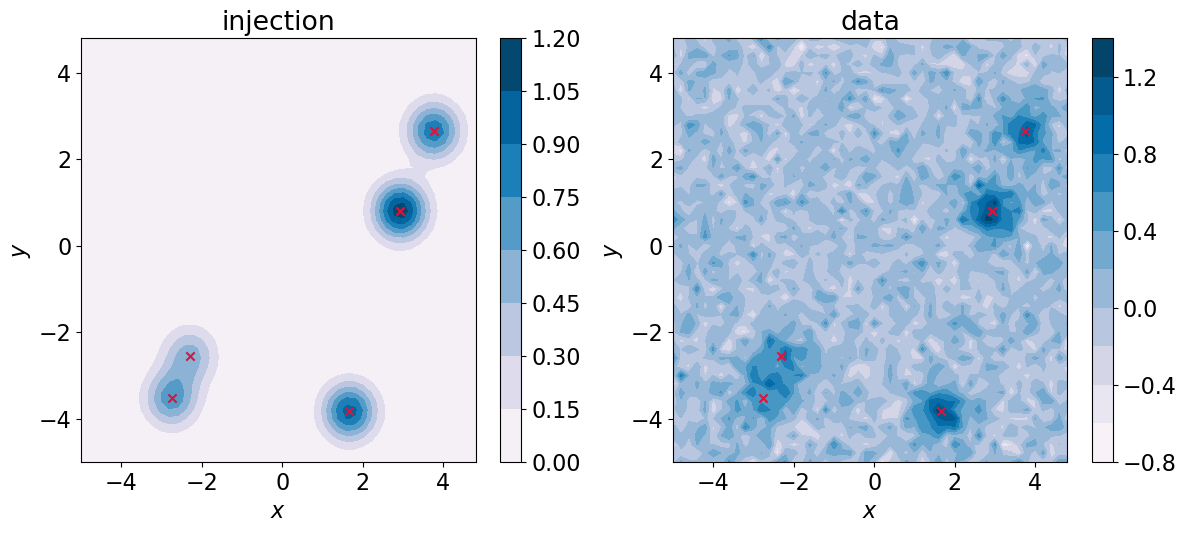

In [4]:
plt.figure(figsize=(14, 5.5))
for i, (img, title) in enumerate([(injection, "injection"), (data, "data")]):
    plt.subplot(1, 2, i + 1)
    cf = plt.contourf(x, y, img, 10, cmap=cm.PuBu)
    plt.scatter(params[:, 1], params[:, 2], marker='x', color='#DC143C')
    plt.colorbar(cf)
    plt.xlabel(r'$x$'); plt.ylabel(r'$y$'); plt.title(title)
plt.show()

## Model, priors and starting point (as in the tutorial)

Two branches: `pulse` (RJ, 1 to 10 pulses with $A, x, y$) and `noise` ($\sigma$). Every walker starts with all 10 leaves switched on, each drawn from the prior. All samplers start from this same state.

In [5]:
ndims        = {"pulse": 3, "noise": 1}
nleaves_max  = {"pulse": 2*npulses, "noise": 1}
nleaves_min  = {"pulse": 1, "noise": 1}
branch_names = ["pulse", "noise"]

priors = {
    "pulse": {
        0: uniform_dist(0.5, 2.),
        1: uniform_dist(lowlim, highlim),
        2: uniform_dist(lowlim, highlim),
    },
    "noise": {
        0: uniform_dist(0.000001, 2.),
    }
}

ntemps = 10
nwalkers = 20
betas = np.linspace(1.0, 0.0, ntemps)

coords = {
    name: ProbDistContainer(priors[name]).rvs(size=(ntemps, nwalkers, nleaves_max[name]))
    for name in branch_names
}
inds = {name: np.ones((ntemps, nwalkers, nleaves_max[name]), dtype=bool) for name in branch_names}

groups = {
    name: np.repeat(np.arange(ntemps * nwalkers).reshape(ntemps, nwalkers)[:, :, None],
                    nleaves_max[name], axis=-1)
    for name in branch_names
}
log_prob = log_prob_fn(
    [coords["pulse"][inds["pulse"]], coords["noise"][inds["noise"]]],
    [groups["pulse"][inds["pulse"]], groups["noise"][inds["noise"]]],
    x, y, data,
)

## Sampling

The three runs differ only in the in-model move for the pulses. Each iteration updates the two branches one after the other, in a Gibbs scheme, with `CombineMove`: first a `GaussianMove` on `noise` (covariance $10^{-4}$, as in the tutorial), then the pulse move, each with its own Metropolis-Hastings accept/reject. The pulse moves are:

* **Gaussian**: the tutorial's `GaussianMove` with covariance $10^{-4}\,I$, moving all pulses of a walker at once.
* **Leaf pool AM**: `LeafPoolAMMove`, moving all active pulses of a walker, with the covariance of the $k$ nearest pooled leaves.
* **Leaf pool stretch**: `LeafPoolStretchMove`, moving all active pulses of a walker, each toward a friend drawn from the same $k$ nearest pooled leaves. Because all $m$ leaves of a walker are accepted or rejected together, the stretch range shrinks with $m$ ($a_m = 2^{1/\sqrt m}$, about 1.36 for $m = 5$), as the AM step does.

The pool keeps the last 75 snapshots, taken every 20 calls: about $75 \times 20 = 1500$ samples per source (one per walker and snapshot). Both moves use the default $k$ = 10% of that, i.e. $k = 150$. It is frozen at the end of burn-in. After the in-model moves, every iteration runs the same RJ birth/death move (`rj_moves=True`, i.e. `DistributionGenerateRJ`): a birth draws the new pulse from the prior, a death removes a randomly chosen active pulse.

We store every second iteration from the start (`burn=0` in `run_mcmc`, `thin_by=2`), so that we can watch the convergence. The first `burn` iterations are discarded afterwards.

In [6]:
burn, nsteps, thin = 6000, 4000, 2     # burn-in iterations, kept samples after burn-in, thinning
nburn = burn // thin                     # stored samples during burn-in
factor = 1e-4


def noise_move():
    return GaussianMove({"noise": np.diag(np.ones(1)) * factor}, gibbs_sampling_setup="noise")


pulse_moves = {
    "Gaussian": lambda: GaussianMove({"pulse": np.diag(np.ones(3)) * factor}, gibbs_sampling_setup="pulse"),
    "Leaf pool AM": lambda: LeafPoolAMMove("pulse", n_snap=75, freeze_after=burn),
    "Leaf pool stretch": lambda: LeafPoolStretchMove("pulse", n_snap=75, freeze_after=burn),
}


def run(name, seed=1):
    """Run the sampler with the named pulse move from the common starting state."""
    move = CombineMove([noise_move(), pulse_moves[name]()])
    ensemble = EnsembleSampler(
        nwalkers, ndims, log_prob_fn, priors,
        args=[x, y, data],
        tempering_kwargs=dict(betas=betas),
        nbranches=len(branch_names), branch_names=branch_names,
        nleaves_max=nleaves_max, nleaves_min=nleaves_min,
        provide_groups=True, vectorize=True,
        moves=move, rj_moves=True,
    )
    np.random.seed(seed)  # the RJ prior draws and temperature swaps use the global generator
    ensemble.random_state = np.random.RandomState(seed).get_state()
    state = State({k: v.copy() for k, v in coords.items()},
                  log_like=log_prob.reshape(ntemps, nwalkers).copy(),
                  betas=betas.copy(), inds={k: v.copy() for k, v in inds.items()})
    t0 = time.time()
    ensemble.run_mcmc(state, nburn + nsteps, burn=0, progress=False, thin_by=thin)
    t = time.time() - t0
    print(f"{name}, seed {seed}: {t:.0f} s")
    return ensemble, t

In [7]:
runs = {name: run(name) for name in pulse_moves}

Gaussian, seed 1: 530 s


Leaf pool AM, seed 1: 1206 s


Leaf pool stretch, seed 1: 973 s


For the quantitative comparison at the end we also need independent replicates: every sampler is run a second time from the same starting state with a different random seed.

In [8]:
runs2 = {name: run(name, seed=2) for name in pulse_moves}

Gaussian, seed 2: 555 s


Leaf pool AM, seed 2: 1213 s


Leaf pool stretch, seed 2: 964 s


## Results

### Convergence from the common start

Cold-chain log-likelihood (mean over walkers) and number of pulses. The dashed line marks the end of burn-in, where the leaf pools are frozen.

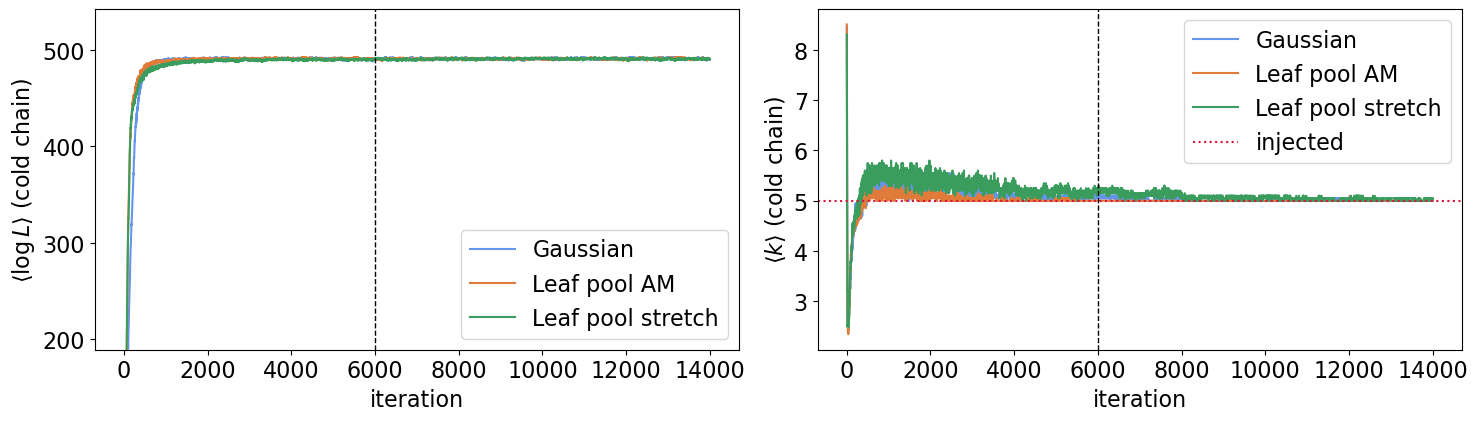

In [9]:
colors = {"Gaussian": "#6495ed", "Leaf pool AM": "#e07b39", "Leaf pool stretch": "#3a9d5d"}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, (ens, _) in runs.items():
    ll = ens.backend.get_log_like()[:, 0]
    k = ens.backend.get_inds()["pulse"][:, 0].sum(-1)
    it = np.arange(1, len(ll) + 1) * thin
    axes[0].plot(it, ll.mean(1), color=colors[name], label=name)
    axes[1].plot(it, k.mean(1), color=colors[name], label=name)
axes[0].set_ylim(ll.mean(1)[nburn:].min() - 300, ll.mean(1).max() + 50)
axes[0].set_ylabel(r"$\langle \log L \rangle$ (cold chain)")
axes[1].axhline(npulses, color="#DC143C", ls=":", label="injected")
axes[1].set_ylabel(r"$\langle k \rangle$ (cold chain)")
for ax in axes:
    ax.axvline(burn, color="k", ls="--", lw=1)
    ax.set_xlabel("iteration")
    ax.legend()
plt.tight_layout()

In [10]:
checks = (300, 1500, 6000, burn + nsteps * thin)
print(f"{'':>18} | " + " | ".join(f"logL@{n:>5}" for n in checks) + f" | <k> post | k={npulses} post")
for name, (ens, _) in runs.items():
    ll = ens.backend.get_log_like()[:, 0].mean(1)
    k = ens.backend.get_inds()["pulse"][nburn:, 0].sum(-1)
    pts = " | ".join(f"{ll[max(n // thin - 30, 0):n // thin].mean():>10.1f}" for n in checks)
    print(f"{name:>18} | {pts} | {k.mean():>8.2f} | {(k == npulses).mean():>9.2f}")

                   | logL@  300 | logL@ 1500 | logL@ 6000 | logL@14000 | <k> post | k=5 post
          Gaussian |      411.9 |      491.6 |      490.6 |      490.7 |     5.01 |      0.99
      Leaf pool AM |      458.7 |      490.0 |      490.8 |      491.3 |     5.00 |      1.00
 Leaf pool stretch |      450.6 |      488.1 |      490.5 |      491.2 |     5.07 |      0.93


### Per-source mixing after burn-in

RJ jumps change which slot holds a source, so we follow sources by position. For each injected pulse, walker and stored sample, we take the active leaf nearest to the injection (within 0.5). We then compute the integrated autocorrelation time $\tau$ of its $A$, $x$, $y$ (in stored samples, i.e. units of 2 iterations), using only sources that are present in at least 99% of the post-burn-in samples. A smaller $\tau$ means more independent samples per step.

In [11]:
def iat(c):
    """Integrated autocorrelation time of c[step, walker] (walker-averaged ACF, Sokal window)."""
    c = c - c.mean(0)
    n = len(c)
    f = np.fft.fft(c, n=2 * n, axis=0)
    acf = np.fft.ifft(f * f.conj(), axis=0)[:n].real.mean(1)
    acf /= acf[0]
    taus = 2 * np.cumsum(acf) - 1
    window = np.arange(n) < 5 * taus
    return taus[np.argmin(window) if not window.all() else n - 1]


def source_tracks(ens, radius=0.5):
    """For each injected pulse: (A, x, y) of the nearest active leaf, and where it is present."""
    P = ens.backend.get_chain()["pulse"][nburn:, 0]           # (steps, walkers, leaves, 3)
    I = ens.backend.get_inds()["pulse"][nburn:, 0]
    tracks = []
    for s in range(npulses):
        d = np.hypot(P[..., 1] - params[s, 1], P[..., 2] - params[s, 2])
        d = np.where(I, d, np.inf)
        j = np.argmin(d, axis=-1)
        leaf = np.take_along_axis(P, j[..., None, None], axis=2)[:, :, 0]
        present = np.take_along_axis(d, j[..., None], axis=-1)[..., 0] < radius
        tracks.append((leaf, present))
    return tracks


tau = {}
for name, (ens, _) in runs.items():
    tau[name] = {}
    for s, (leaf, present) in enumerate(source_tracks(ens)):
        if present.mean() >= 0.99:
            fill = np.where(present[..., None], leaf, leaf[present].mean(0))
            tau[name][s] = [iat(fill[..., p]) for p in range(3)]

common = sorted(set.intersection(*(set(t) for t in tau.values())))
for name in runs:
    print(f"sources found in >=99% of samples, {name}: {sorted(tau[name])}")
print(f"\n{'source':>6} {'A_inj':>6} | " + " | ".join(f"{'tau ' + name + ' (A, x, y)':>34}" for name in runs))
for s in common:
    cols = " | ".join(f"{str(np.round(tau[name][s], 1)):>34}" for name in runs)
    print(f"{s:>6} {params[s, 0]:>6.2f} | {cols}")

sources found in >=99% of samples, Gaussian: [0, 1, 2, 3, 4]
sources found in >=99% of samples, Leaf pool AM: [0, 1, 2, 3, 4]
sources found in >=99% of samples, Leaf pool stretch: [0, 1, 2, 3, 4]

source  A_inj |             tau Gaussian (A, x, y) |         tau Leaf pool AM (A, x, y) |    tau Leaf pool stretch (A, x, y)
     0   0.87 |                      [4.3 4.7 5. ] |                      [4.  3.8 3.7] |                      [4.1 4.6 3.9]
     1   1.45 |                      [5.5 3.3 3.2] |                      [3.9 3.9 3.7] |                      [7.4 4.8 4.2]
     2   1.23 |                      [4.3 3.3 3.5] |                      [3.6 3.5 3.6] |                      [3.9 4.  4.4]
     3   1.10 |                      [4.3 3.4 3.6] |                      [3.3 3.4 3.6] |                      [5.7 5.1 5.4]
     4   0.66 |                      [5.  4.3 4.7] |                      [4.1 3.5 3.6] |                      [4.  4.2 4.5]


In [12]:
nsamp = nsteps * nwalkers
print(f"{'':>18} | {'wall time':>9} | {'median tau':>10} | {'ESS / source':>12} | {'ESS / s':>8}")
for name, (ens, t) in runs.items():
    med = np.median([np.max(v) for s, v in tau[name].items() if s in common]) if common else np.nan
    print(f"{name:>18} | {t:>8.0f}s | {med:>10.1f} | {nsamp / med:>12.0f} | {nsamp / med / t:>8.2f}")
print("\nacceptance fractions (cold chain):")
for name, (ens, _) in runs.items():
    acc = {f"{br}: {type(m).__name__}": round(float(m.accepted[0].mean() / m.num_proposals), 3)
           for br, m in zip(("noise", "pulse"), ens.moves[0].moves)}
    acc["RJ"] = round(float(ens.rj_moves[0].accepted[0].mean() / ens.rj_moves[0].num_proposals), 3)
    print(f"  {name}: {acc}")

                   | wall time | median tau | ESS / source |  ESS / s
          Gaussian |      530s |        5.0 |        16082 |    30.36
      Leaf pool AM |     1206s |        3.9 |        20408 |    16.92
 Leaf pool stretch |      973s |        4.6 |        17397 |    17.88

acceptance fractions (cold chain):
  Gaussian: {'noise: GaussianMove': 0.327, 'pulse: GaussianMove': 0.646, 'RJ': 0.001}
  Leaf pool AM: {'noise: GaussianMove': 0.327, 'pulse: LeafPoolAMMove': 0.616, 'RJ': 0.001}
  Leaf pool stretch: {'noise: GaussianMove': 0.328, 'pulse: LeafPoolStretchMove': 0.407, 'RJ': 0.001}


### Posteriors

Pulse positions and amplitudes (cold chain, after burn-in), the number of pulses and the noise level.

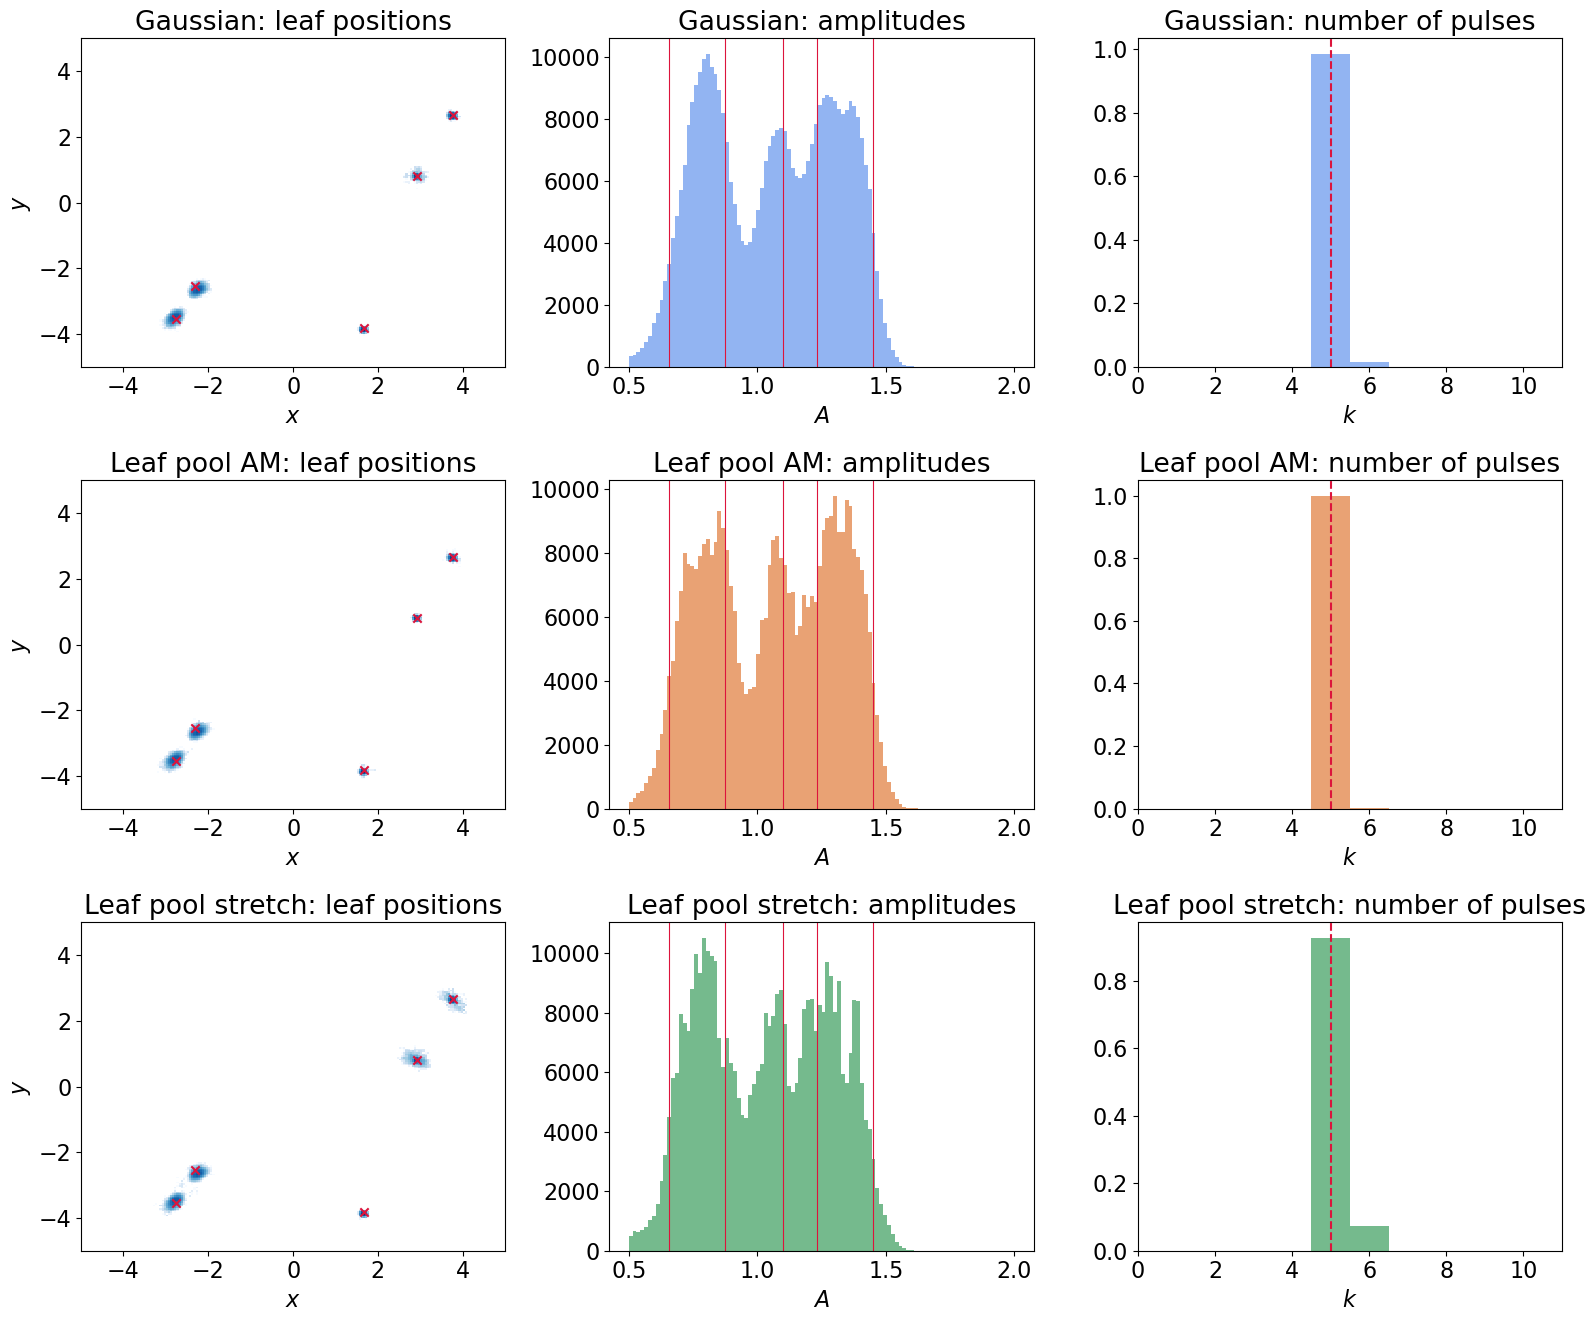

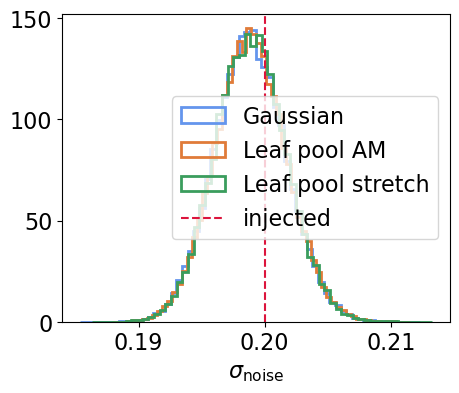

In [13]:
fig, axes = plt.subplots(len(runs), 3, figsize=(16, 4.5 * len(runs)))
for row, (name, (ens, _)) in enumerate(runs.items()):
    P = ens.backend.get_chain()["pulse"][nburn:, 0]
    I = ens.backend.get_inds()["pulse"][nburn:, 0]
    pts = P[I]
    ax = axes[row, 0]
    ax.hist2d(pts[:, 1], pts[:, 2], bins=200, range=[[lowlim, highlim]] * 2, cmap="Blues", norm=LogNorm())
    ax.scatter(params[:, 1], params[:, 2], marker="x", color="#DC143C")
    ax.set_title(f"{name}: leaf positions"); ax.set_xlabel("$x$"); ax.set_ylabel("$y$")

    ax = axes[row, 1]
    ax.hist(pts[:, 0], bins=100, range=(0.5, 2), color=colors[name], histtype="stepfilled", alpha=0.7)
    for a in params[:, 0]:
        ax.axvline(a, color="#DC143C", lw=0.8)
    ax.set_title(f"{name}: amplitudes"); ax.set_xlabel("$A$")

    ax = axes[row, 2]
    k = I.sum(-1).ravel()
    ax.hist(k, bins=np.arange(0.5, nleaves_max["pulse"] + 1.5), density=True, color=colors[name], alpha=0.7)
    ax.axvline(npulses, color="#DC143C", ls="--")
    ax.set_title(f"{name}: number of pulses"); ax.set_xlabel("$k$")
plt.tight_layout()

plt.figure(figsize=(5, 4))
for name, (ens, _) in runs.items():
    s = ens.backend.get_chain()["noise"][nburn:, 0, :, 0, 0].ravel()
    plt.hist(s, bins=60, density=True, histtype="step", lw=2, color=colors[name], label=name)
plt.axvline(sigma_noise[0][0], color="#DC143C", ls="--", label="injected")
plt.xlabel(r"$\sigma_\mathrm{noise}$"); plt.legend(); plt.show()

## Zoom on one source

The marginal of one pulse, from the leaves within 0.5 of the injection, for all runs. All samplers target the same posterior, so these should agree; what differs is how many independent samples they deliver.

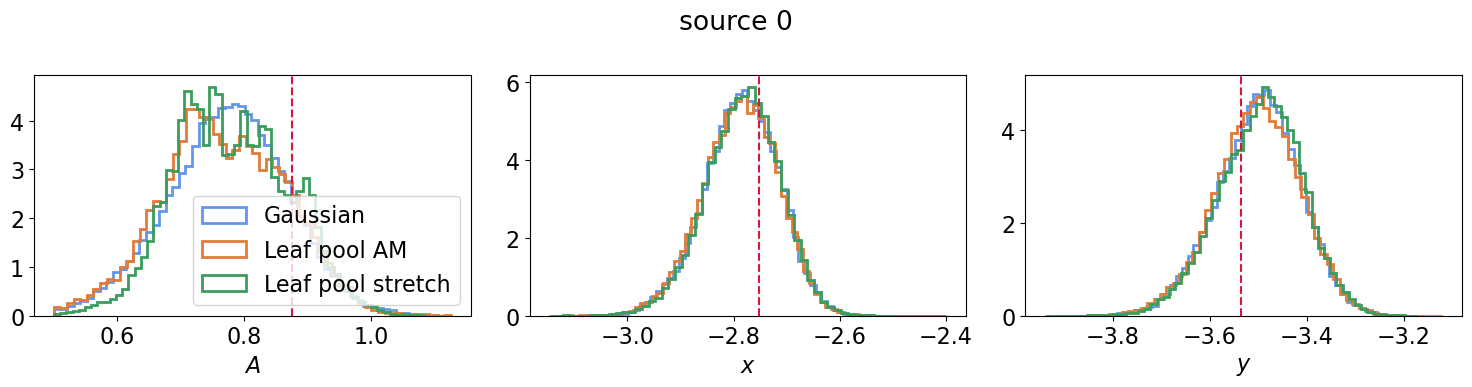

In [14]:
s = common[0] if common else 0
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = ["$A$", "$x$", "$y$"]
for name, (ens, _) in runs.items():
    leaf, present = source_tracks(ens)[s]
    v = leaf[present]
    for p, ax in enumerate(axes):
        ax.hist(v[:, p], bins=60, density=True, histtype="step", lw=2, color=colors[name], label=name)
for p, ax in enumerate(axes):
    ax.axvline(params[s, p], color="#DC143C", ls="--")
    ax.set_xlabel(labels[p])
axes[0].legend()
plt.suptitle(f"source {s}")
plt.tight_layout()

## Quantitative comparison: Jensen-Shannon divergence

To compare the posteriors quantitatively, we compute the Jensen-Shannon divergence (JSD, in bits; 0 for identical distributions, 1 for disjoint ones) between pairs of runs for every one-dimensional marginal: $A$, $x$, $y$ of each source found in at least half of the samples of all six runs (tracked as above), $\sigma_\mathrm{noise}$ and the number of pulses $k$. Continuous marginals are histogrammed on 50 common bins.

A finite run gives a non-zero JSD even between two samplers with the same target, from sampling noise and from incomplete convergence. To calibrate this floor, we compare each sampler with **its own independent replicate** (same start, different seed). Splitting one run into two halves of walkers would not do: all walkers start from the same state and share the same residual drift, so the halves agree better than independent runs do. Each between-sampler JSD is averaged over the two seed pairings (seed 1 against seed 1, seed 2 against seed 2), so all numbers use the same sample sizes. If two samplers sample the same posterior, their JSD should be comparable with their seed-to-seed floors.

In [15]:
from itertools import combinations
from scipy.spatial.distance import jensenshannon


def jsd(a, b, bins=50, discrete=False):
    """Jensen-Shannon divergence (bits) between two 1D samples on common bins."""
    if discrete:
        edges = np.arange(min(a.min(), b.min()) - 0.5, max(a.max(), b.max()) + 1.5)
    else:
        lo, hi = np.percentile(np.concatenate([a, b]), [0.1, 99.9])
        edges = np.linspace(lo, hi, bins + 1)
    pa, _ = np.histogram(a, bins=edges)
    pb, _ = np.histogram(b, bins=edges)
    return jensenshannon(pa, pb, base=2) ** 2


def marginals(ens):
    """All 1D marginals of the cold chain after burn-in."""
    out = {}
    for s, (leaf, present) in enumerate(source_tracks(ens)):
        if s in jsd_src:
            for p, lab in enumerate("Axy"):
                out[f"{lab}{s}"] = leaf[..., p][present]
    out["sigma"] = ens.backend.get_chain()["noise"][nburn:, 0, :, 0, 0].ravel()
    out["k"] = ens.backend.get_inds()["pulse"][nburn:, 0].sum(-1).ravel()
    return out


# sources found (within 0.5 of the injection) in at least half of the samples of all six runs
names = list(runs)
reps = {name: (runs[name][0], runs2[name][0]) for name in names}
pres = np.array([[present.mean() for _, present in source_tracks(e)] for name in names for e in reps[name]])
jsd_src = [s for s in range(npulses) if pres[:, s].min() >= 0.5]
print("fraction of samples with the source present (rows: " + ", ".join(f"{n} {i}" for n in names for i in (1, 2)) + "):")
print(np.round(pres, 3))
print(f"sources used for the JSD: {jsd_src}\n")

M = {name: [marginals(e) for e in reps[name]] for name in names}
keys = list(M[names[0]][0])
pairs = list(combinations(names, 2))
cols = [f"{a} vs {b}" for a, b in pairs] + [f"{n}, seeds" for n in names]
J = {}
for key in keys:
    disc = key == "k"
    J[key] = [np.mean([jsd(M[a][h][key], M[b][h][key], discrete=disc) for h in (0, 1)]) for a, b in pairs]
    J[key] += [jsd(M[n][0][key], M[n][1][key], discrete=disc) for n in names]

short = {"Gaussian": "G", "Leaf pool AM": "AM", "Leaf pool stretch": "S"}
heads = [f"{short[a]}-{short[b]}" for a, b in pairs] + [f"{short[n]} seeds" for n in names]
print(f"{'marginal':>8} | " + " | ".join(f"{h:>9}" for h in heads))
for key in keys:
    print(f"{key:>8} | " + " | ".join(f"{v:>9.4f}" for v in J[key]))
print("(G = Gaussian, AM = leaf pool AM, S = leaf pool stretch)\n")
src = [k for k in keys if k not in ("sigma", "k")]
if src:
    for i, c in enumerate(cols):
        v = np.array([J[k][i] for k in src])
        print(f"source marginals, {c:>36}: median {np.median(v):.4f}, max {v.max():.4f} ({src[v.argmax()]})")

fraction of samples with the source present (rows: Gaussian 1, Gaussian 2, Leaf pool AM 1, Leaf pool AM 2, Leaf pool stretch 1, Leaf pool stretch 2):
[[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]]
sources used for the JSD: [0, 1, 2, 3, 4]



marginal |      G-AM |       G-S |      AM-S |   G seeds |  AM seeds |   S seeds
      A0 |    0.0045 |    0.0116 |    0.0141 |    0.0012 |    0.0160 |    0.0102
      x0 |    0.0007 |    0.0010 |    0.0012 |    0.0016 |    0.0016 |    0.0008
      y0 |    0.0012 |    0.0013 |    0.0018 |    0.0024 |    0.0025 |    0.0020
      A1 |    0.0063 |    0.0221 |    0.0304 |    0.0032 |    0.0072 |    0.0174
      x1 |    0.0006 |    0.0035 |    0.0050 |    0.0005 |    0.0016 |    0.0032
      y1 |    0.0006 |    0.0018 |    0.0032 |    0.0005 |    0.0005 |    0.0025
      A2 |    0.0045 |    0.0178 |    0.0258 |    0.0021 |    0.0118 |    0.0247
      x2 |    0.0004 |    0.0013 |    0.0019 |    0.0002 |    0.0006 |    0.0034
      y2 |    0.0005 |    0.0005 |    0.0007 |    0.0003 |    0.0004 |    0.0009
      A3 |    0.0039 |    0.0110 |    0.0143 |    0.0008 |    0.0030 |    0.0190
      x3 |    0.0005 |    0.0010 |    0.0009 |    0.0005 |    0.0005 |    0.0012
      y3 |    0.0005 |    0.

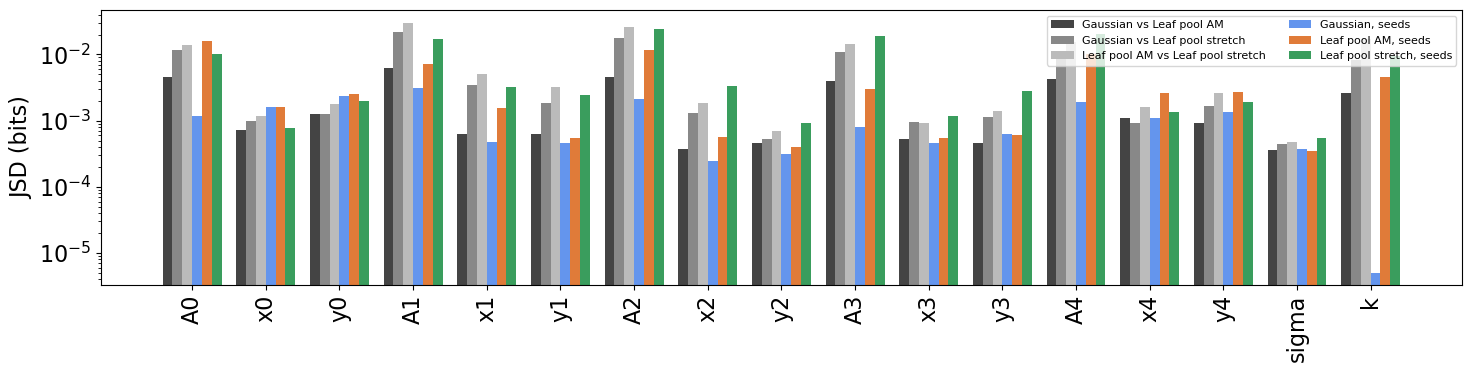

In [16]:
fig, ax = plt.subplots(figsize=(15, 4))
pos = np.arange(len(keys))
w = 0.8 / len(cols)
bar_colors = ["#444444", "#888888", "#bbbbbb"] + [colors[n] for n in names]
for i, (c, col) in enumerate(zip(cols, bar_colors)):
    ax.bar(pos + (i - (len(cols) - 1) / 2) * w, [J[k][i] for k in keys], width=w, color=col, label=c)
ax.set_xticks(pos)
ax.set_xticklabels(keys, rotation=90)
ax.set_ylabel("JSD (bits)")
ax.set_yscale("log")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()

## Summary

All three samplers find the five injected pulses and agree on the posterior. They differ in how fast they get there and in what an independent sample costs (seed 1, 4000 post-burn-in iterations, cold chain):

| pulse move | pulse acceptance | median $\tau$ | ESS / source | wall time | ESS / s | $P(k=5)$ | JSD between seeds (median) |
|---|---|---|---|---|---|---|---|
| `GaussianMove` (hand-tuned) | 0.65 | 5.0 | 16 100 | 530 s | 30 | 0.99 | 0.0011 |
| `LeafPoolAMMove` | 0.62 | 3.9 | 20 400 | 1206 s | 17 | 1.00 | 0.0025 |
| `LeafPoolStretchMove` | 0.41 | 4.6 | 17 400 | 973 s | 18 | 0.93 | 0.0028 |

* **`LeafPoolAMMove`** needs no tuning and mixes best per iteration:
  * It has the shortest autocorrelation time and the most effective samples per source.
  * It is the fastest to reach the high-likelihood region from the common start (log-likelihood 459 at iteration 300, against 412 for the Gaussian), and it settles on $k = 5$ by the end of burn-in.
  * Its posterior agrees with the Gaussian run as well as two seeds of the Gaussian agree with each other (median JSD 0.0009 against 0.0011).
* **`LeafPoolStretchMove`** mixes about as well as the Gaussian within each source:
  * The number of pulses converges more slowly: $\langle k \rangle$ stays slightly above 5 until about iteration 9000, which shows in the lower $P(k=5)$.
  * About a third of its proposals are rejected by the reverse check alone (see the introduction).
  * Its posterior agrees with the other two within the run-to-run scatter. The largest differences are in the amplitudes (JSD up to 0.03).
* **Cost.** Both leaf-pool moves take about twice the wall time of the Gaussian per iteration. The extra time goes to the nearest-neighbour searches, two per moved leaf and iteration, and, for AM, the local covariances. Their ESS per second is therefore about half the Gaussian's here. This overhead does not depend on the likelihood. In this example the likelihood is very cheap; with an expensive one, for example waveform models, it becomes a small fraction of the run.

`LeafPoolAMMove` is therefore a good default in-model move for RJ branches whose sources are well separated: it replaces the hand-tuned Gaussian, with no tuning and no loss of accuracy. `LeafPoolStretchMove` also samples the right posterior, but it needs a longer burn-in to settle the number of sources.